In [962]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [963]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.load_master_data import load_master_data

df = load_master_data()

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null  category      
 10  time                               8354 non-n

In [964]:
target = "podium"

df[target].value_counts()

df[target].value_counts(normalize=True)

podium
0    0.865916
1    0.134084
Name: proportion, dtype: float64

In [965]:
features = [
    "grid",
    "qualifying_position",
    "driver_age",
    "pole_position",
    "front_row",
    "constructor_name",
    "driver_nationality",
    "circuit_country",
    "current_season_points",
    "avg_points_per_season",
    "constructor_points_current_season",
    "points_last_5_races"
]

descriminative_numerical_features = []
descriminative_categorical_features = []

In [966]:
X = df[features]

y = df[target]

In [967]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   grid                               25939 non-null  int64   
 1   qualifying_position                11029 non-null  float64 
 2   driver_age                         25939 non-null  float64 
 3   pole_position                      25939 non-null  int64   
 4   front_row                          25939 non-null  int64   
 5   constructor_name                   25939 non-null  category
 6   driver_nationality                 25939 non-null  category
 7   circuit_country                    25939 non-null  category
 8   current_season_points              25939 non-null  float64 
 9   avg_points_per_season              25939 non-null  float64 
 10  constructor_points_current_season  25939 non-null  float64 
 11  points_last_5_races                25939 non-null  f

## GRID T TEST

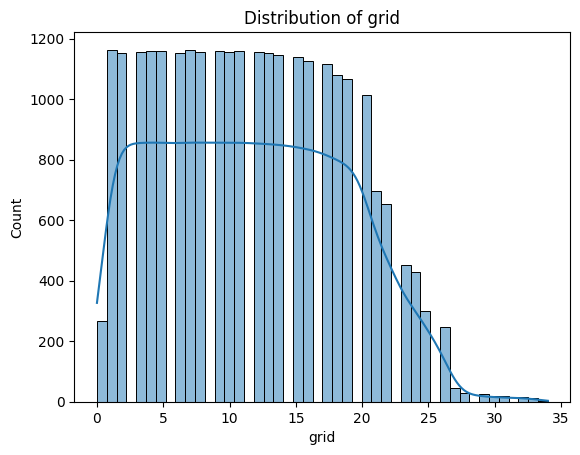

In [968]:
from src.hist import hist

hist(df, "grid")

In [969]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["grid"]

non_podium_group = df[
    df["podium"] == 0
]["grid"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'grid' is discriminative.")
    descriminative_numerical_features.append("grid")
else:
    print("Fail to reject H0")
    print("The variable 'grid' is class independent.")

U-statistic: 9878160.5
P-value: 0.0
Reject H0
The variable 'grid' is discriminative.


### Hypothesis Test for Grid Position

H0: The variable 'grid' is class independent.

H1: The variable 'grid' is not class independent.

Confidence level = 95%
α = 0.05

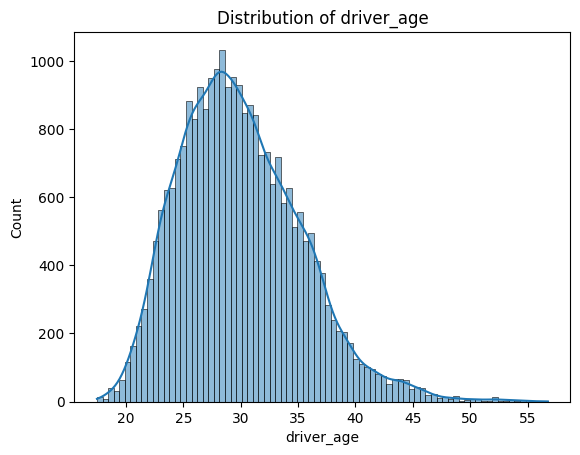

In [970]:
hist(df, "driver_age")

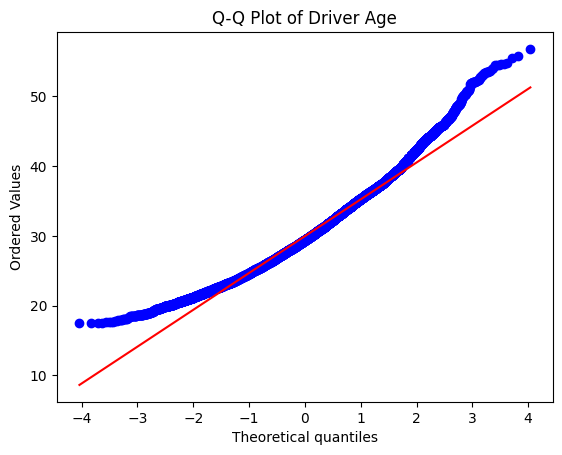

In [971]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(
    df["driver_age"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Driver Age")

plt.show()

In [972]:
from scipy.stats import mannwhitneyu


# Separate groups
podium_group = df[
    df["podium"] == 1
]["driver_age"]

non_podium_group = df[
    df["podium"] == 0
]["driver_age"]

# T-test
t_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    nan_policy="omit"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'driver_age' is discriminative.")
    descriminative_numerical_features.append("driver_age")
else:
    print("Fail to reject H0")
    print("The variable 'driver_age' is class independent.")

T-statistic: 42559063.5
P-value: 1.656553146433306e-17
Reject H0
The variable 'driver_age' is discriminative.


In [973]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["front_row"],
    df["podium"]
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Front row starts are associated with podium finishes.")
    descriminative_categorical_features.append("front_row")
else:
    print("Fail to reject H0")
    print("Front row starts are independent of podium finishes.")

Chi-square statistic: 4045.2462825884727
P-value: 0.0
Reject H0
Front row starts are associated with podium finishes.


In [974]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["constructor_name"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor name is associated with podium finishes.")
    descriminative_categorical_features.append("constructor_name")
else:
    print("Fail to reject H0")
    print("Constructor name is independent of podium finishes.")

Chi-square statistic: 3711.3602882742834
P-value: 0.0
Reject H0
Constructor name is associated with podium finishes.


In [975]:
# Contingency table
contingency_table = pd.crosstab(
    df["circuit_country"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)


alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Circuit country is associated with podium finishes.")
    descriminative_categorical_features.append("circuit_country")
else:
    print("Fail to reject H0")
    print("Circuit country is independent of podium finishes.")

Chi-square statistic: 9.27955285158374
P-value: 0.999984847062557
Fail to reject H0
Circuit country is independent of podium finishes.


In [976]:
# Contingency table
contingency_table = pd.crosstab(
    df["driver_nationality"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Driver nationality is associated with podium finishes.")
    descriminative_categorical_features.append("driver_nationality")
else:
    print("Fail to reject H0")
    print("Driver nationality is independent of podium finishes.")

Chi-square statistic: 795.4696292875008
P-value: 8.634066317202463e-142
Reject H0
Driver nationality is associated with podium finishes.


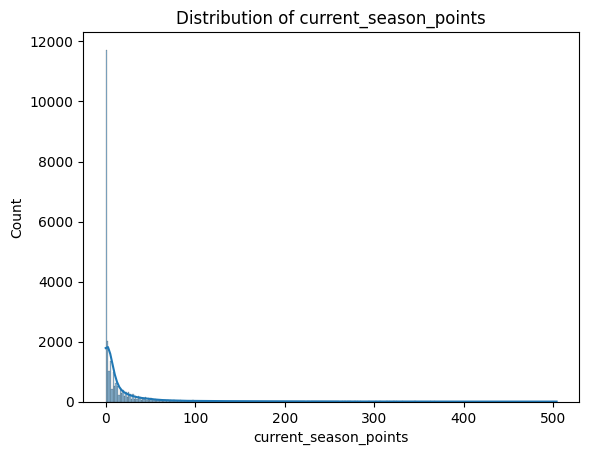

In [977]:
hist(
    df,
    "current_season_points")

In [978]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["current_season_points"]

non_podium_group = df[
    df["podium"] == 0
]["current_season_points"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Current season points is discriminative.")
    descriminative_numerical_features.append("current_season_points")
else:
    print("Fail to reject H0")
    print("Current season points is class independent.")

U-statistic: 58953609.0
P-value: 0.0
Reject H0
Current season points is discriminative.


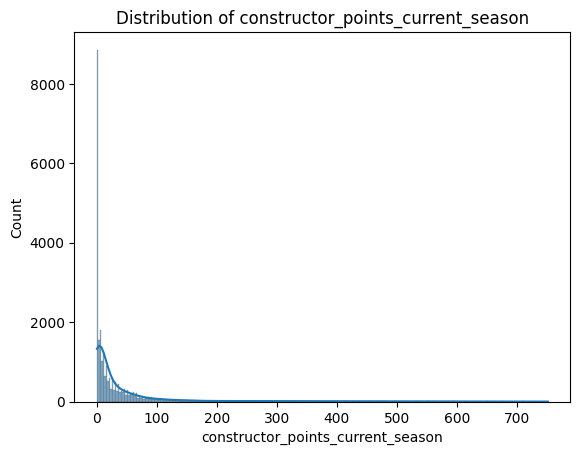

In [979]:
hist(df, "constructor_points_current_season")

In [980]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["constructor_points_current_season"]

non_podium_group = df[
    df["podium"] == 0
]["constructor_points_current_season"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor points is discriminative.")
    descriminative_numerical_features.append("constructor_points_current_season")
else:
    print("Fail to reject H0")
    print("Constructor points is class independent.")

U-statistic: 58249338.5
P-value: 0.0
Reject H0
Constructor points is discriminative.


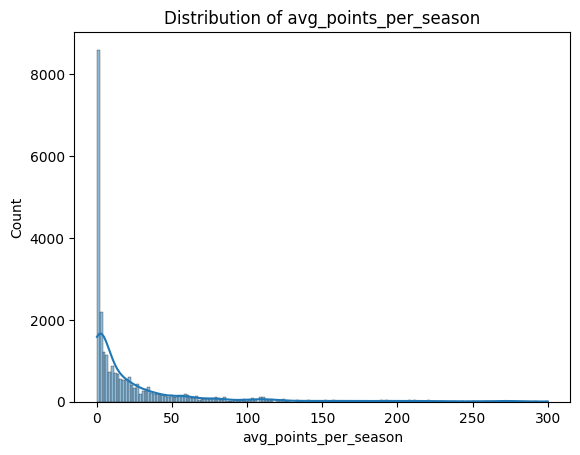

In [981]:
hist(df, "avg_points_per_season")

In [982]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["avg_points_per_season"]

non_podium_group = df[
    df["podium"] == 0
]["avg_points_per_season"]
# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Average points per season is discriminative.")
    descriminative_numerical_features.append("avg_points_per_season")
else:
    print("Fail to reject H0")
    print("Average points per season is class independent.")

U-statistic: 57611119.0
P-value: 0.0
Reject H0
Average points per season is discriminative.


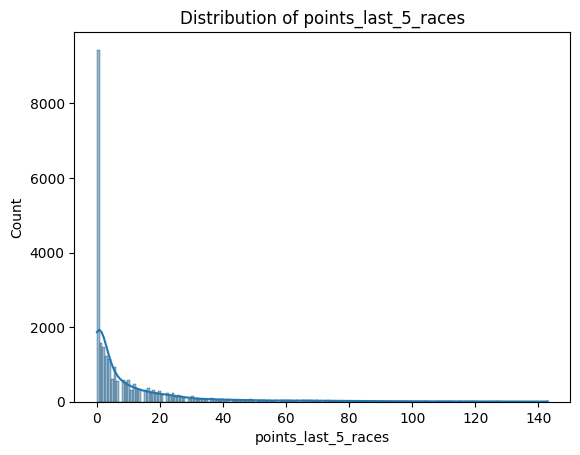

In [983]:
hist(df, "points_last_5_races")

In [984]:
podium_group = df[
    df["podium"] == 1
]["points_last_5_races"]

non_podium_group = df[
    df["podium"] == 0
]["points_last_5_races"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("points_last_5_races is discriminative.")
    descriminative_numerical_features.append("points_last_5_races")

else:
    print("Fail to reject H0")
    print("points_last_5_races is class independent.")

U-statistic: 63661232.5
P-value: 0.0
Reject H0
points_last_5_races is discriminative.


In [985]:
correlation_matrix = (
    df[descriminative_numerical_features]
    .corr()
)

correlation_matrix

,grid,driver_age,current_season_points,constructor_points_current_season,avg_points_per_season,points_last_5_races
grid,1.000000,-0.057301,-0.350153,-0.342130,-0.330706,-0.459572
driver_age,-0.057301,1.000000,-0.029959,-0.015882,0.099421,-0.013952
current_season_points,-0.350153,-0.029959,1.000000,0.954218,0.638751,0.785826
constructor_points_current_season,-0.342130,-0.015882,0.954218,1.000000,0.591487,0.736425
avg_points_per_season,-0.330706,0.099421,0.638751,0.591487,1.000000,0.736505
points_last_5_races,-0.459572,-0.013952,0.785826,0.736425,0.736505,1.000000


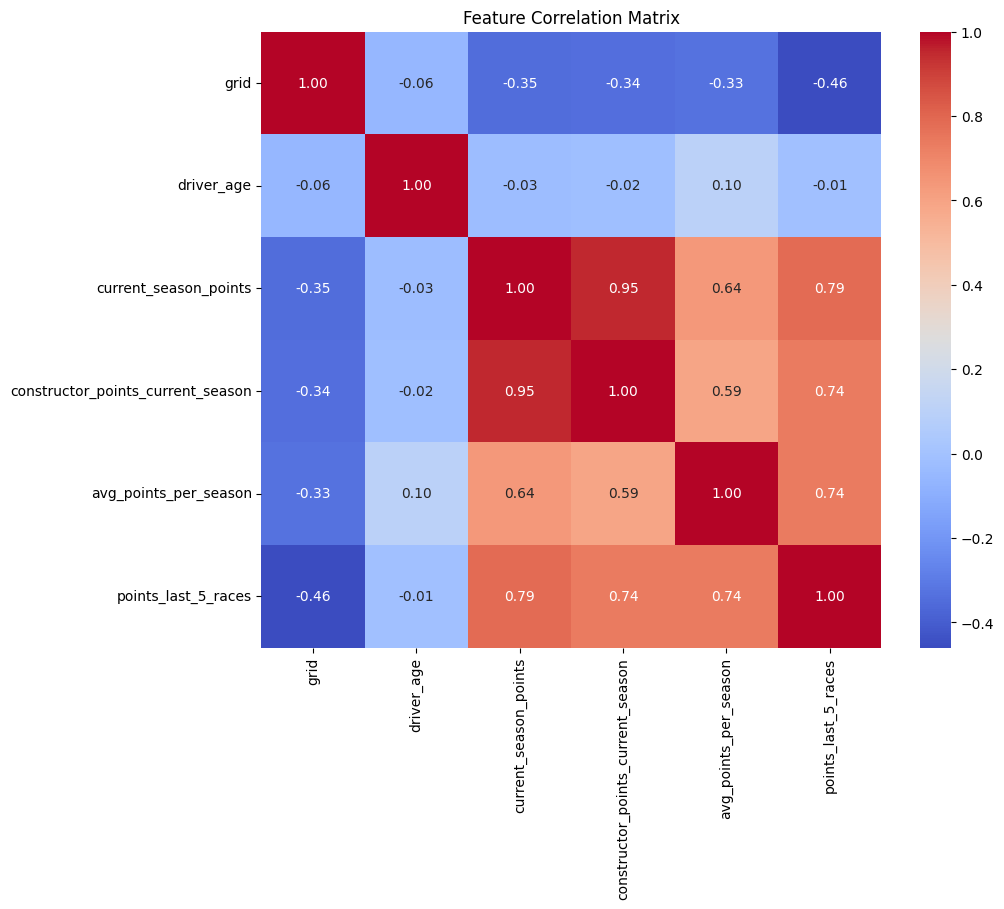

In [986]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [987]:
corr_matrix = (
    df[descriminative_numerical_features]
    .corr()
    .abs()
)

# Upper triangle only
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Find features with correlation > 0.9
high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.9)
]

print(high_corr_features)

['constructor_points_current_season']


In [988]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):

    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(contingency_table)[0]

    n = contingency_table.sum().sum()

    r, k = contingency_table.shape

    return np.sqrt(
        chi2 / (n * (min(r, k) - 1))
    )

In [989]:
cramers_matrix = pd.DataFrame(
    index=descriminative_categorical_features,
    columns=descriminative_categorical_features
)

for col1 in descriminative_categorical_features:
    for col2 in descriminative_categorical_features:

        cramers_matrix.loc[col1, col2] = (
            cramers_v(
                df[col1],
                df[col2]
            )
        )

cramers_matrix

,front_row,constructor_name,driver_nationality
front_row,0.999785,0.323896,0.157325
constructor_name,0.323896,1.0,0.369019
driver_nationality,0.157325,0.369019,1.0


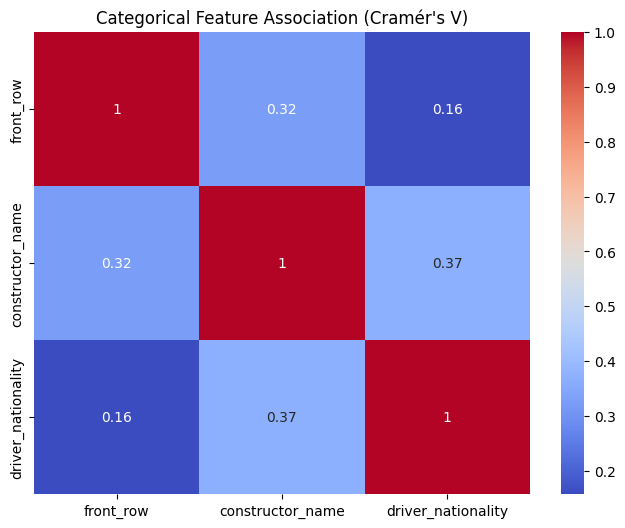

In [990]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cramers_matrix.astype(float),
    annot=True,
    cmap="coolwarm"
)

plt.title("Categorical Feature Association (Cramér's V)")

plt.show()

In [1002]:
final_features = (
    descriminative_numerical_features +
    descriminative_categorical_features
)

for f in high_corr_features:
    if f in final_features:
        print(f"Removing {f} due to high correlation.")
        final_features.remove(f)

final_features

Removing constructor_points_current_season due to high correlation.


['grid',
 'driver_age',
 'current_season_points',
 'avg_points_per_season',
 'points_last_5_races',
 'front_row',
 'constructor_name',
 'driver_nationality']

In [1003]:
X = df[final_features]

y = df["podium"]

In [1004]:
from sklearn.model_selection import train_test_split

from src.models.logistic_regression import (
    prepare_data,
    train_logistic_regression
)

from src.models.evaluate import (
    evaluate_model
)

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)

X_train_scaled, X_test_scaled, scaler = (
    prepare_data(
        X_train,
        X_test
    )
)

model = train_logistic_regression(
    X_train_scaled,
    y_train
)

y_pred = model.predict(
    X_test_scaled
)

evaluate_model(
    y_test,
    y_pred
)

Accuracy: 0.7827679259830378
              precision    recall  f1-score   support

           0       0.97      0.77      0.86      4492
           1       0.37      0.86      0.52       696

    accuracy                           0.78      5188
   macro avg       0.67      0.82      0.69      5188
weighted avg       0.89      0.78      0.81      5188

[[3460 1032]
 [  95  601]]


In [1005]:
from sklearn.model_selection import (
    train_test_split
)

from src.models.random_forest import (
    prepare_data,
    train_random_forest
)

from src.models.evaluate import (
    evaluate_model
)

# Split

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)

# Prepare

X_train_prepared, X_test_prepared = (
    prepare_data(
        X_train,
        X_test
    )
)

# Train

rf_model = train_random_forest(
    X_train_prepared,
    y_train
)

# Predict

y_pred_rf = rf_model.predict(
    X_test_prepared
)

# Evaluate

evaluate_model(
    y_test,
    y_pred_rf
)

Accuracy: 0.8157286044718581
              precision    recall  f1-score   support

           0       0.96      0.82      0.88      4492
           1       0.41      0.81      0.54       696

    accuracy                           0.82      5188
   macro avg       0.69      0.81      0.71      5188
weighted avg       0.89      0.82      0.84      5188

[[3670  822]
 [ 134  562]]


In [1006]:
feature_importance = pd.DataFrame({
    "feature": X_train_prepared.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
0,grid,0.248469
4,points_last_5_races,0.181506
2,current_season_points,0.127160
3,avg_points_per_season,0.113831
5,front_row,0.111456
...,...,...
200,constructor_name_Turner,0.000000
188,constructor_name_Sutton,0.000000
194,constructor_name_Token,0.000000
220,driver_nationality_Czech,0.000000


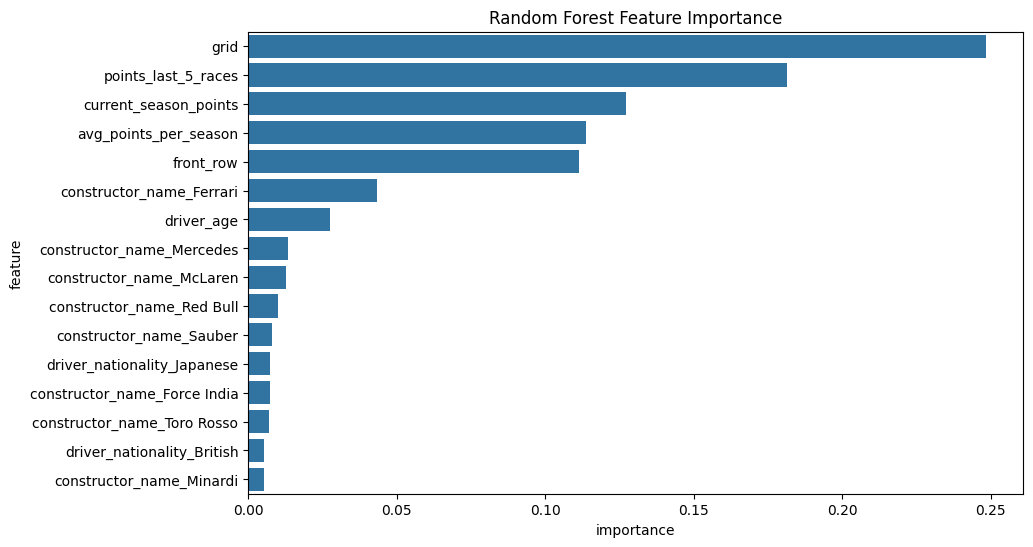

In [1007]:
important_features = feature_importance[
    feature_importance["importance"] > 0.005
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

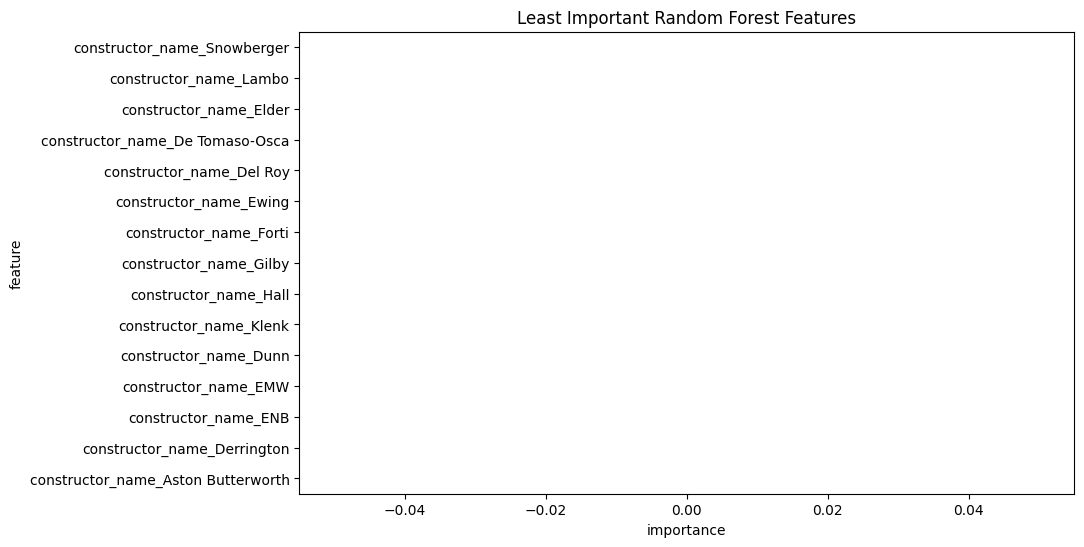

In [1008]:
# Least important features

least_important = (
    feature_importance
    .sort_values(by="importance", ascending=True)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=least_important,
    x="importance",
    y="feature"
)

plt.title("Least Important Random Forest Features")

plt.show()

In [1019]:
from src.data.preprocessing import (
    prepare_chronological_data
)

X_train, X_test, y_train, y_test, _ = (
    prepare_chronological_data(
        df,
        features,
        scale=False
    )
)

In [1035]:
from src.models.random_forest import (
    train_random_forest )

rf_model = train_random_forest(
    X_train,
    y_train
)

In [1036]:
y_prob = rf_model.predict_proba(X_test)[:, 1]

y_pred_custom = (
    y_prob > 0.68
).astype(int)

In [1038]:
from src.models.evaluate import (
    evaluate_model)

evaluate_model(
    y_test,
    y_pred_custom
)

Accuracy: 0.8690775478630826
              precision    recall  f1-score   support

           0       0.96      0.88      0.92      4406
           1       0.54      0.79      0.64       765

    accuracy                           0.87      5171
   macro avg       0.75      0.84      0.78      5171
weighted avg       0.90      0.87      0.88      5171

[[3890  516]
 [ 161  604]]


In [1039]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
0,grid,0.238042
8,points_last_5_races,0.142056
6,avg_points_per_season,0.105488
5,current_season_points,0.100607
7,constructor_points_current_season,0.080793
...,...,...
32,constructor_name_Boro,0.000000
30,constructor_name_Bellasi,0.000000
27,constructor_name_BRM-Ford,0.000000
250,driver_nationality_Uruguayan,0.000000


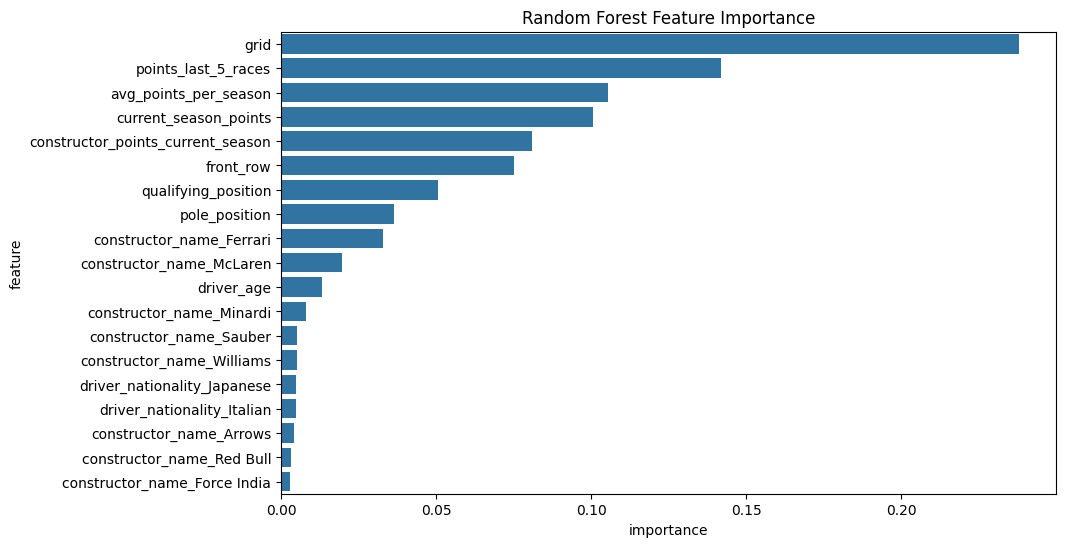

In [1040]:
important_features = feature_importance[
    feature_importance["importance"] > 0.002
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()